In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load best model
model = keras.models.load_model(
    "/content/drive/MyDrive/wildfire_prediction_model_final.h5"
)

class_names = ["nowildfire", "wildfire"]
IMG_SIZE = 224


In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input
import numpy as np
from PIL import Image

def preprocess_image(image_path):
    img = Image.open(image_path).convert("RGB")
    img_resized = img.resize((IMG_SIZE, IMG_SIZE))

    img_array = np.array(img_resized)          # ✅ FIRST define it
    img_array = preprocess_input(img_array)    # ✅ THEN preprocess
    img_array = np.expand_dims(img_array, axis=0)

    return img_resized, img_array


In [ ]:
def predict_and_plot(image_path):
    original_img, img_array = preprocess_image(image_path)

    # Prediction
    prob = model.predict(img_array)[0][0]
    pred_label = class_names[int(prob > 0.4)]
    confidence = prob if prob > 0.5 else 1 - prob

    # Plot
    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(original_img)
    plt.title("Uploaded Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(original_img)
    plt.title(
        f"Prediction: {pred_label}\nConfidence: {confidence:.2%}",
        color="green" if pred_label == "wildfire" else "blue"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step


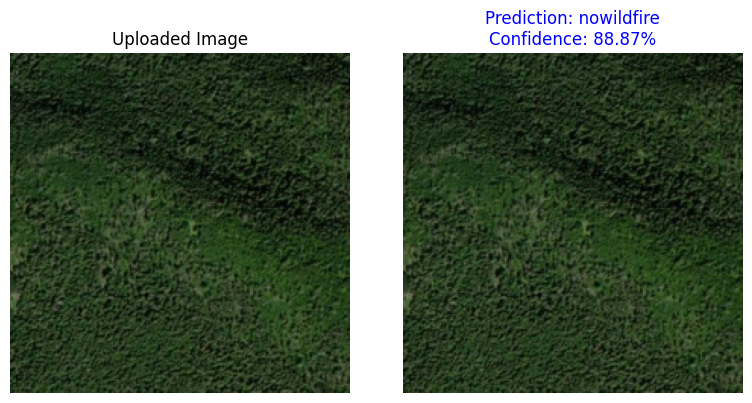

In [ ]:
predict_and_plot("/content/drive/MyDrive/test/-64.88374,49.04587.jpg")
